# Zgodność anotacji - stary prompt (Wykop, próba 1)

Pierwsza runda walidacji. Trzy osoby (Mikołaj, Patrycja, Zuza) niezależnie oznaczyły te same
150 wpisów z Wykopu etykietami `ai`, `work` i `stance`. Porównujemy je ze sobą i z modelem
`qwen3:8b` z **pierwotnym promptem** (`72f3a1da`), który oceniał wszystkie trzy etykiety naraz.

- `ai` - czy wpis dotyczy sztucznej inteligencji (`yes`/`no`),
- `work` - czy wpis dotyczy pracy, kariery lub rynku pracy (`yes`/`no`),
- `ai+work` - obie naraz; to filtr, który decyduje, co trafia do dalszej analizy,
- `stance` - co autor mówi o wpływie AI na pracę: `threat`, `reassurance`, `opportunity`,
  `mixed`, `none`.

Próba nie była czysto losowa: zawiera dużo wpisów, które model oznaczył jako `threat`.

In [1]:
import sys
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, "..")
from amc.classification.job_concern import PROMPT_HASH, YES_NO  # noqa: E402
from amc.classification.job_concern_details import STANCE  # noqa: E402

pd.set_option("display.max_colwidth", 200)
plt.rcParams["figure.figsize"] = (10, 4)

DATA = Path("../data/wykop")
KEY = ["type", "entry_id"]
SEED = 20261025
CATEGORIES = {"ai": YES_NO, "work": YES_NO, "ai+work": YES_NO, "stance": STANCE}

## Konfiguracja

In [2]:
ANNOTATION_FILES = {
    "Mikołaj": DATA / "Anotacje_Wykop_Mikołaj.xlsx",
    "Patrycja": DATA / "Anotacje_Wykop_Patrycja.xlsx",
    "Zuza": DATA / "Anotacje_Wykop_Zuza.xlsx",
}
LABELS = ["ai", "work", "stance"]  # etykiety anotatorów
MODEL_FILE = DATA / "wykop_classified.csv"
MODEL_PROMPT = "72f3a1da"  # początek prompt_hash
MODEL_LABELS = ["ai", "work", "stance"]
BASELINE = None  # (plik, nazwa) - drugi model do porównania
OUT = DATA / "agreement" / "old_prompt"

## Wczytanie danych

In [3]:
def clean(df, labels):
    """Etykiety małymi literami; wartości spoza słownika (np. puste) stają się brakiem."""
    df = df.reset_index(drop=True).copy()
    for label in labels:
        values = df[label].fillna("").astype(str).str.strip().str.lower()
        df[label] = values.where(values.isin(CATEGORIES[label]))
    if "ai" in labels and "work" in labels:
        both = df["ai"].eq("yes") & df["work"].eq("yes")
        df["ai+work"] = np.where(both, "yes", "no")
        df.loc[df["ai"].isna() | df["work"].isna(), "ai+work"] = np.nan
    return df


def load_annotations(path):
    df = pd.read_excel(path, sheet_name="sample", dtype=str).dropna(subset=["entry_id"])
    return clean(df, LABELS)


OUT.mkdir(parents=True, exist_ok=True)
sheets = {name: load_annotations(path) for name, path in ANNOTATION_FILES.items()}
ANNOTATORS = list(sheets)
base = sheets[ANNOTATORS[0]][[*KEY, "created_at", "url", "text"]]
for name, df in sheets.items():
    assert df[KEY].equals(base[KEY]), f"{name}: inne wpisy lub kolejność"
    missing = df[LABELS].isna().sum()
    if missing.any():
        print(f"{name}: brak poprawnej odpowiedzi -> {missing[missing > 0].to_dict()}")
print("wpisów:", len(base), "| anotatorzy:", ANNOTATORS)


def load_labels(path, labels, prompt=None):
    df = pd.read_csv(path, dtype=str, encoding="utf-8-sig")
    if prompt is not None:
        df = df[df["prompt_hash"].str.startswith(prompt)]
    df = base[KEY].merge(df, on=KEY, how="left", validate="one_to_one")
    assert df[labels[0]].notna().all(), f"{path.name}: brak etykiet dla części wpisów"
    return clean(df, labels)


ratings = dict(sheets)
model = load_labels(MODEL_FILE, MODEL_LABELS, MODEL_PROMPT)
ratings["model"] = model
print("model:", model["model"].dropna().unique(), "| prompt:", MODEL_PROMPT[:8])
if BASELINE is not None:
    ratings[BASELINE[1]] = load_labels(BASELINE[0], ["ai", "work"])
RATERS = list(ratings)
ALL_LABELS = [*LABELS[:2], "ai+work", *LABELS[2:]] if "work" in LABELS else LABELS


def raters_for(label):
    return [r for r in RATERS if label in ratings[r].columns]

wpisów: 150 | anotatorzy: ['Mikołaj', 'Patrycja', 'Zuza']
model: ['qwen3:8b'] | prompt: 72f3a1da


## Rozkład etykiet

In [4]:
pd.concat(
    {
        label: pd.DataFrame(
            {r: ratings[r][label].value_counts() for r in raters_for(label)}
        ).reindex(CATEGORIES[label])
        for label in ALL_LABELS
    }
).astype("Int64")

Mikołaj  Patrycja  Zuza  model
ai      yes               64        68    61     83
        no                86        82    89     67
work    yes               95       103    94    119
        no                55        47    56     31
ai+work yes               38        42    34     75
        no               112       108   116     75
stance  threat            17        16    16     51
        reassurance        3         4     2      2
        opportunity        9         8     7      8
        mixed           <NA>         1  <NA>   <NA>
        none             121       121   125     89

## Miary zgodności

- **zgodność %** - odsetek par ocen, które są takie same;
- **kappa Cohena** - dla pary oceniających (także model z człowiekiem), z poprawką na
  zgodność przypadkową wynikającą z rozkładu etykiet każdego z nich;
- **kappa Fleissa** - jedna liczba dla wszystkich anotatorów naraz.

Przedziały ufności 95% z bootstrapu po wpisach (2000 losowań). Wpisy z brakującą odpowiedzią
są pomijane tylko w porównaniach, których dotyczą.

In [5]:
def labels_of(label, raters):
    """Macierz wpis x oceniający; wiersze z jakimkolwiek brakiem są pomijane."""
    values = pd.concat([ratings[r][label].rename(r) for r in raters], axis=1).dropna()
    return values.to_numpy(dtype=object), values.index


def percent_agreement(values):
    """Odsetek zgodnych par ocen; dla dwóch oceniających to odsetek identycznych ocen."""
    m = values.shape[1]
    counts = np.stack([(values == c).sum(axis=1) for c in np.unique(values)], axis=1)
    return (((counts**2).sum(axis=1) - m) / (m * (m - 1))).mean()


def cohen_kappa(values):
    a, b = values[:, 0], values[:, 1]
    p_o = np.mean(a == b)
    p_e = sum(np.mean(a == c) * np.mean(b == c) for c in np.union1d(a, b))
    return (p_o - p_e) / (1 - p_e) if p_e < 1 else np.nan


def fleiss_kappa(values):
    counts = np.stack([(values == c).sum(axis=1) for c in np.unique(values)], axis=1)
    p_e = ((counts.sum(axis=0) / counts.sum()) ** 2).sum()
    p_o = percent_agreement(values)
    return (p_o - p_e) / (1 - p_e) if p_e < 1 else np.nan


def bootstrap(statistic, values, iterations=2000, seed=SEED):
    rng = np.random.default_rng(seed)
    draws = [
        statistic(values[rng.integers(0, len(values), len(values))]) for _ in range(iterations)
    ]
    low, high = np.nanpercentile(draws, [2.5, 97.5])
    return f"[{low:.2f}, {high:.2f}]"


def landis_koch(value):
    """Opis słowny według Landisa i Kocha (1977)."""
    if np.isnan(value):
        return ""
    for limit, name in [(0, "brak"), (0.2, "niewielka"), (0.4, "dostateczna"),
                        (0.6, "umiarkowana"), (0.8, "znaczna")]:
        if value <= limit:
            return name
    return "prawie pełna"


# Kontrola wzorów: pełna zgodność daje 1, a oceny losowe i niezależne około 0
check = np.array([["yes", "yes"], ["no", "no"], ["yes", "yes"], ["no", "no"]], dtype=object)
assert np.isclose(cohen_kappa(check), 1) and np.isclose(fleiss_kappa(check), 1)
noise = np.random.default_rng(1).choice(["yes", "no"], size=(20000, 2)).astype(object)
assert abs(cohen_kappa(noise)) < 0.03 and abs(fleiss_kappa(noise)) < 0.03

## 1. Zgodność między anotatorami

In [6]:
rows = []
for label in ALL_LABELS:
    values, _ = labels_of(label, ANNOTATORS)
    kappa = fleiss_kappa(values)
    rows.append({
        "etykieta": label,
        "wpisów": len(values),
        "zgodność %": percent_agreement(values),
        "kappa Fleissa": kappa,
        "95% CI": bootstrap(fleiss_kappa, values),
        "ocena": landis_koch(kappa),
    })
humans = pd.DataFrame(rows).set_index("etykieta")
humans.to_csv(OUT / "agreement_annotators.csv", encoding="utf-8-sig")
humans.round(3)

,wpisów,zgodność %,kappa Fleissa,95% CI,ocena
etykieta,,,,,
ai,150,0.942,0.882,"[0.81, 0.94]",prawie pełna
work,150,0.898,0.776,"[0.69, 0.86]",znaczna
ai+work,150,0.938,0.836,"[0.75, 0.91]",prawie pełna
stance,150,0.909,0.715,"[0.60, 0.82]",znaczna


## 2. Kappa Cohena dla każdej pary oceniających

In [7]:
pairs = []
for label in ALL_LABELS:
    for a, b in combinations(raters_for(label), 2):
        values, _ = labels_of(label, [a, b])
        pairs.append({
            "etykieta": label,
            "para": f"{a} - {b}",
            "rodzaj": "człowiek - człowiek" if {a, b} <= set(ANNOTATORS) else "z modelem",
            "wpisów": len(values),
            "zgodność %": np.mean(values[:, 0] == values[:, 1]),
            "kappa Cohena": cohen_kappa(values),
            "95% CI": bootstrap(cohen_kappa, values),
        })
pairs = pd.DataFrame(pairs)
pairs.to_csv(OUT / "cohen_pairs.csv", index=False, encoding="utf-8-sig")
pairs.pivot(index="para", columns="etykieta", values="kappa Cohena").round(3)

etykieta,ai,ai+work,stance,work
para,,,,
Mikołaj - Patrycja,0.838,0.796,0.660,0.674
Mikołaj - Zuza,0.959,0.890,0.829,0.957
Mikołaj - model,0.593,0.453,0.402,0.431
Patrycja - Zuza,0.851,0.824,0.660,0.691
Patrycja - model,0.644,0.560,0.419,0.659
Zuza - model,0.582,0.453,0.400,0.452


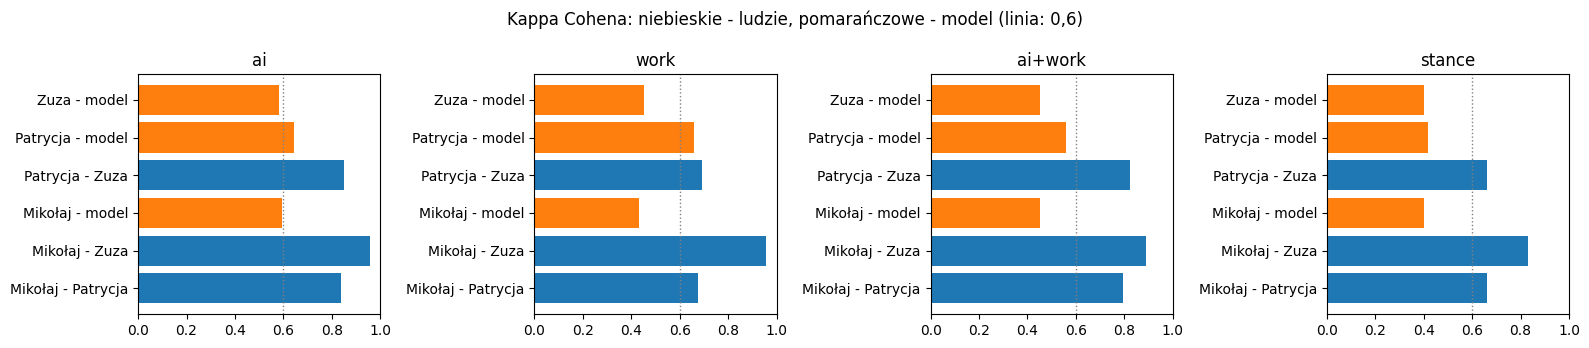

In [8]:
fig, axes = plt.subplots(1, len(ALL_LABELS), figsize=(4 * len(ALL_LABELS), 3.5))
for ax, label in zip(np.atleast_1d(axes), ALL_LABELS):
    part = pairs[pairs["etykieta"] == label]
    colors = np.where(part["rodzaj"] == "z modelem", "tab:orange", "tab:blue")
    ax.barh(part["para"], part["kappa Cohena"], color=colors)
    ax.axvline(0.6, color="grey", ls=":", lw=1)
    ax.set_title(label)
    ax.set_xlim(min(0, part["kappa Cohena"].min() - 0.05), 1)
fig.suptitle("Kappa Cohena: niebieskie - ludzie, pomarańczowe - model (linia: 0,6)")
plt.tight_layout()
plt.savefig(OUT / "cohen_pairs.png", dpi=120)
plt.show()

## 3. Model a etykieta złota

In [9]:
def gold_label(label):
    """Odpowiedź co najmniej dwojga anotatorów; przy dwóch - tylko gdy oboje się zgadzają."""
    votes = pd.concat([ratings[a][label] for a in ANNOTATORS], axis=1)
    result = []
    for row in votes.itertuples(index=False):
        counts = pd.Series(row).dropna().value_counts()
        top = counts.index[0] if len(counts) else None
        ok = len(counts) and counts.iloc[0] >= 2 and (len(counts) == 1 or counts.iloc[1] < counts.iloc[0])
        result.append(top if ok else np.nan)
    return pd.Series(result, dtype=object)


gold = pd.DataFrame({label: gold_label(label) for label in ALL_LABELS})
ratings["złota"] = gold
pd.DataFrame({
    "z etykietą złotą": gold.notna().sum(),
    "bez (spór lub brak)": gold.isna().sum(),
})

,z etykietą złotą,bez (spór lub brak)
ai,150,0
work,150,0
ai+work,150,0
stance,149,1


In [10]:
def per_class(truth, predicted, categories):
    rows = []
    for c in categories:
        tp = np.sum((predicted == c) & (truth == c))
        fp = np.sum((predicted == c) & (truth != c))
        fn = np.sum((predicted != c) & (truth == c))
        precision = tp / (tp + fp) if tp + fp else np.nan
        recall = tp / (tp + fn) if tp + fn else np.nan
        f1 = 2 * precision * recall / (precision + recall) if precision + recall else np.nan
        rows.append({"kategoria": c, "złota": tp + fn, "model": tp + fp,
                     "precyzja": precision, "czułość": recall, "F1": f1})
    return pd.DataFrame(rows).set_index("kategoria")


MODELS = [r for r in RATERS if r not in ANNOTATORS]
human_mean = pairs[pairs["rodzaj"] == "człowiek - człowiek"].groupby("etykieta")["kappa Cohena"].mean()
rows = []
for name in MODELS:
    for label in [lab for lab in ALL_LABELS if lab in ratings[name].columns]:
        values, _ = labels_of(label, ["złota", name])
        kappa = cohen_kappa(values)
        yes = per_class(values[:, 0], values[:, 1], ["yes"]).iloc[0] if label != "stance" else None
        rows.append({
            "model": name,
            "etykieta": label,
            "wpisów": len(values),
            "trafność": np.mean(values[:, 0] == values[:, 1]),
            "kappa Cohena": kappa,
            "95% CI": bootstrap(cohen_kappa, values),
            "ocena": landis_koch(kappa),
            "precyzja yes": yes["precyzja"] if yes is not None else np.nan,
            "czułość yes": yes["czułość"] if yes is not None else np.nan,
            "kappa ludzi (średnia par)": human_mean.get(label, np.nan),
        })
vs_gold = pd.DataFrame(rows).set_index(["model", "etykieta"])
vs_gold.to_csv(OUT / "model_vs_gold.csv", encoding="utf-8-sig")
vs_gold.round(3)

wpisów  trafność  kappa Cohena        95% CI        ocena  \
model etykieta                                                              
model ai           150     0.793         0.594  [0.47, 0.71]  umiarkowana   
      work         150     0.773         0.463  [0.31, 0.61]  umiarkowana   
      ai+work      150     0.740         0.480  [0.36, 0.60]  umiarkowana   
      stance       149     0.732         0.428  [0.30, 0.55]  umiarkowana   

                precyzja yes  czułość yes  kappa ludzi (średnia par)  
model etykieta                                                        
model ai               0.687        0.919                      0.882  
      work             0.756        0.947                      0.774  
      ai+work          0.480        1.000                      0.837  
      stance             NaN          NaN                      0.716

### Macierze pomyłek i miary per kategoria

In [11]:
for name in MODELS:
    for label in [lab for lab in ALL_LABELS if lab in ratings[name].columns]:
        values, _ = labels_of(label, ["złota", name])
        cats = CATEGORIES[label]
        print(f"\n=== {name}: {label} (wiersze: złota, kolumny: {name})")
        display(pd.crosstab(
            pd.Categorical(values[:, 0], cats), pd.Categorical(values[:, 1], cats),
            rownames=["złota"], colnames=[name], dropna=False,
        ))
        scores = per_class(values[:, 0], values[:, 1], cats)
        scores.to_csv(OUT / f"per_class_{name}_{label}.csv".replace(" ", "_"), encoding="utf-8-sig")
        display(scores.round(3))


=== model: ai (wiersze: złota, kolumny: model)


model,yes,no
złota,,
yes,57,5
no,26,62


,złota,model,precyzja,czułość,F1
kategoria,,,,,
yes,62,83,0.687,0.919,0.786
no,88,67,0.925,0.705,0.800



=== model: work (wiersze: złota, kolumny: model)


model,yes,no
złota,,
yes,90,5
no,29,26


...

model,yes,no
złota,,
yes,36,0
no,39,75


,złota,model,precyzja,czułość,F1
kategoria,,,,,
yes,36,75,0.48,1.000,0.649
no,114,75,1.00,0.658,0.794



=== model: stance (wiersze: złota, kolumny: model)


model,threat,reassurance,opportunity,mixed,none
złota,,,,,
threat,16,0,0,0,1
reassurance,1,1,0,0,0
opportunity,1,1,5,0,1
mixed,0,0,0,0,0
none,32,0,3,0,87


,złota,model,precyzja,czułość,F1
kategoria,,,,,
threat,17,50,0.320,0.941,0.478
reassurance,2,2,0.500,0.500,0.500
opportunity,8,8,0.625,0.625,0.625
mixed,0,0,NaN,NaN,NaN
none,122,89,0.978,0.713,0.825


## 4. Rozbieżności do omówienia

Wpisy, w których model różni się od etykiety złotej, oraz wpisy, przy których anotatorzy się
różnili. Zapisujemy je do folderu wyników.

In [12]:
def show(mask, labels):
    columns = {}
    for label in labels:
        for rater in [*raters_for(label), "złota"]:
            if label in ratings[rater].columns:
                columns[f"{label}: {rater}"] = ratings[rater][label]
    view = pd.DataFrame({
        "url": base["url"],
        "text": base["text"].str.replace("\n", " ").str.slice(0, 300),
        **columns,
    })
    return view[mask.to_numpy()]


model_labels = [lab for lab in ALL_LABELS if lab in model.columns]
model_split = pd.Series(False, index=base.index)
for label in model_labels:
    model_split |= gold[label].notna() & model[label].ne(gold[label])
human_split = pd.Series(False, index=base.index)
for label in LABELS:
    votes = pd.concat([ratings[a][label] for a in ANNOTATORS], axis=1)
    human_split |= votes.nunique(axis=1, dropna=False) > 1
print("model inaczej niż złota:", model_split.sum(), "| anotatorzy niezgodni:", human_split.sum())

show(model_split, model_labels).to_csv(OUT / "model_vs_gold_rows.csv", encoding="utf-8-sig")
show(human_split, LABELS).to_csv(OUT / "annotators_split.csv", encoding="utf-8-sig")
show(model_split, model_labels)

model inaczej niż złota: 73 | anotatorzy niezgodni: 47


,url,text,ai: Mikołaj,ai: Patrycja,ai: Zuza,ai: model,ai: złota,work: Mikołaj,work: Patrycja,work: Zuza,...,ai+work: Mikołaj,ai+work: Patrycja,ai+work: Zuza,ai+work: model,ai+work: złota,stance: Mikołaj,stance: Patrycja,stance: Zuza,stance: model,stance: złota
0,https://wykop.pl/wpis/82295773/tak-to-ja-nie-chce-0-0-chatgpt,Tak to ja nie chce #chatgpt,no,yes,no,yes,no,no,no,no,...,no,no,no,no,no,none,none,none,none,none
2,https://wykop.pl/wpis/71287435/chatgpt-nie-zabierze-ci-pracy-jesli-odpowiednio-go,"ChatGPT nie zabierze Ci pracy, jeśli odpowiednio go wytresujesz xd #openai #chatgpt #programowanie #heheszki",yes,yes,yes,yes,yes,yes,yes,yes,...,yes,yes,yes,yes,yes,opportunity,opportunity,opportunity,reassurance,opportunity
4,https://wykop.pl/wpis/58542797/dzisiaj-kolejny-dzien-jebania-w-kontraktorni-posre,Dzisiaj kolejny dzień j-----a w kontraktorni/pośredniaku na projekt który z góry miał datę dostarczenia jak jeszcze nie było programistów. Macie z---------ć by dowieźć i elo. #przegryw #korposw...,no,no,no,yes,no,yes,yes,yes,...,no,no,no,yes,no,none,none,none,threat,none
6,https://wykop.pl/wpis/72771881/uznalbym-to-za-anomalie-gdybym-rano-nie-mogl-na-pr,"Uznałbym to za anomalię, gdybym rano nie mógł na pracowych tagach poczytać o tym, jakie to IT złe, a próba wejścia do branży skazana na niepowodzenie i zostanie menelem ( ͡° ͜ʖ ͡°) No to siadamy, ...",no,no,no,yes,no,yes,yes,yes,...,no,no,no,yes,no,none,none,none,threat,none
7,https://wykop.pl/wpis/66489879/klepie-kod-w-skandynawskiej-firmie-lajtowa-robota-,"Klepie kod w skandynawskiej firmie lajtowa robota w sumie na 5 dni przepracuje może 2... nikt nie weryfikuje mojej pracy dosłownie mogę sobie wpisać, że pracowałem 8h nad taskiem który nie istniej...",no,no,no,yes,no,yes,yes,yes,...,no,no,no,yes,no,none,none,none,threat,none
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
136,https://wykop.pl/wpis/51570169/anonimowemirkowyznania-czy-3500-zl-netto-dla-junio,"#anonimowemirkowyznania Czy 3500 zł netto dla junior #machinelearning engineer to jest dobra pensja w #warszawa? Nie mam ściśle komercyjnego doświadczenia, ale mam #doktorat z uczenia maszynowego...",yes,yes,yes,yes,yes,no,yes,no,...,no,yes,no,yes,no,none,none,none,none,none
137,https://wykop.pl/wpis/66489725/jak-zbudowac-swoje-programistyczne-portfolio-jakie,Jak Zbudować Swoje Programistyczne Portfolio? Jakie Funkcje Warto Dodać Do Swojej Aplikacji? Cześć Właśnie pojawił się nowy artykuł na blogu Modest Programmer. W tym artykule przede wszystkim o...,no,no,no,no,no,yes,no,yes,...,no,no,no,no,no,none,none,none,none,none
139,https://wykop.pl/wpis/79938613/wystarczyl-jeden-chinski-model-open-source-i-juz-c,"Wystarczył jeden chiński model open source i już cała amerykańska #gielda w--------a się na ryj. Hochsztapler Altman i tak długo dawał radę robic inwestorów w c---a nowymi ""ulepszonymi"" wersjami ...",yes,yes,yes,yes,yes,no,no,no,...,no,no,no,yes,no,none,none,none,threat,none
145,https://wykop.pl/wpis/85492073/to-teraz-pierwszy-etap-rekrutacji-to-jest-rozmowa-,To teraz pierwszy etap rekrutacji to jest rozmowa z AI? XDDDD #pracait #programista15k #programowanie,yes,yes,yes,yes,yes,yes,yes,yes,...,yes,yes,yes,yes,yes,threat,threat,threat,none,threat


In [13]:
show(human_split, LABELS)

,url,text,ai: Mikołaj,ai: Patrycja,ai: Zuza,ai: model,ai: złota,work: Mikołaj,work: Patrycja,work: Zuza,work: model,work: złota,stance: Mikołaj,stance: Patrycja,stance: Zuza,stance: model,stance: złota
0,https://wykop.pl/wpis/82295773/tak-to-ja-nie-chce-0-0-chatgpt,Tak to ja nie chce #chatgpt,no,yes,no,yes,no,no,no,no,no,no,none,none,none,none,none
5,https://wykop.pl/wpis/79344903/programowanie-programista15k-programista25k-pracba,"#programowanie #programista15k #programista25k #pracbaza #java #pracait #kryzysit #korposwiat A i jeszcze jedno odnośnie kwestia pasjonatów. Pasjonaci tak p------ą, że IT to taka rozwojowa branża...",yes,yes,no,yes,yes,yes,yes,yes,yes,yes,threat,threat,none,threat,threat
16,https://wykop.pl/wpis/82789411/czyli-mamy-byc-januszami-ai-biznesu-i-aireczki-trz,Czyli mamy być Januszami AI biznesu i AIreczki trzeba kruciutko pod butem i batem. Ehhh czyli wkraczamy w erę leniwych systemów ktore trzeba pilnować i dopraszac sie #ai #sztucznainteligencja #he...,yes,yes,yes,yes,yes,yes,yes,yes,yes,yes,threat,none,threat,threat,threat
17,https://wykop.pl/wpis/69380449/chatgpt-openai-wojsko-no-i-co-mirki-myslicie-ze-mi,"#chatgpt #openai #wojsko No i co mirki, myślicie, że minister się przychili do kobiecej prośby? Swoją drogą zabawne, że mi ten list wygenerował jako kobieta. Jak sprawdzałem inne rzeczy, to pi...",yes,yes,yes,no,yes,yes,no,no,no,no,opportunity,none,none,none,none
21,https://wykop.pl/wpis/77288965/programista15k-jak-niby-rozpoznaje-sie-seniora-w-c,#programista15k jak niby rozpoznaje się seniora w cv? W umowie nie mam żadnego stopniowania a byłem nawet managerem projektu bez zmiany umowy. Stopniowanie jest bez sensu jak i zadania rekrutacyjn...,yes,yes,yes,yes,yes,yes,yes,yes,yes,yes,threat,none,threat,threat,threat
31,https://wykop.pl/wpis/45656173/sa-jakies-ksiazki-czy-inne-opracowania-na-temat-co,"są jakieś książki czy inne opracowania na temat co bedzie, gdy sztuczna intelignecja bedzie doskonała, wszystko bedą wykonywały roboty itd. jakieś rozważania co z czlowiekiem, czy bedzie taki czło...",no,yes,no,yes,no,yes,yes,yes,yes,yes,none,none,none,none,none
35,https://wykop.pl/wpis/71187023/darmowa-oraz-okrojona-wersja-gpt4-gdyby-ktos-chcia,"Darmowa oraz okrojona wersja gpt4 gdyby ktos chciał, bez logowania https://gpt4login.com/use-chatgpt-online-free/ #gpt4 #ai #zadarmotouczciwacena",no,yes,no,yes,no,yes,no,yes,no,yes,none,none,none,none,none
36,https://wykop.pl/wpis/81570767/chatgpt-nie-chce-mi-powiedziec-co-mam-zrobic-z-pla,"#chatgpt nie chce mi powiedzieć co mam zrobić z plaga myszy i sugeruje wezwanie fachowca który pewnie weźmie z 200zł, dobrze że są alternatywy",no,yes,no,yes,no,yes,no,yes,yes,yes,none,none,none,threat,none
39,https://wykop.pl/wpis/82079563/odkryj-jak-stworzyc-wlasny-kanal-youtube-przy-uzyc,"Odkryj, jak stworzyć własny kanał YouTube przy użyciu darmowych narzędzi AI! W tym poradniku pokażę Ci krok po kroku, jak generować scenariusze, głos, wideo i montować profesjonalne filmy bez wyda...",yes,yes,yes,yes,yes,yes,no,yes,yes,yes,opportunity,none,opportunity,opportunity,opportunity
44,https://wykop.pl/wpis/82269865/skrot-dzisiejszych-wiadomosci-ze-swiata-technologi,Skrót dzisiejszych wiadomości ze świata technologii #codziennytech #sztucznainteligencja #technologia #wydarzenia #komputery #informatyka #ciekawostki #programowanie #gruparatowaniapoziomu **Ubis...,yes,no,yes,yes,yes,no,no,no,yes,no,none,none,none,threat,none


## Jak czytać wyniki

- **Ludzie między sobą.** Kappa powyżej 0,8 to zgodność prawie pełna, 0,6-0,8 znaczna
  (Landis i Koch 1977). Jeśli jest niska, problemem jest definicja etykiety, nie model -
  najpierw doprecyzujcie wytyczne na podstawie listy rozbieżności.
- **Model.** Jeśli kappa model-człowiek mieści się w zakresie kapp człowiek-człowiek, model
  może zastąpić anotatora. Jeśli jest wyraźnie niższa, trzeba poprawić prompt albo model.
- **`ai+work`** to filtr do dalszej analizy: precyzja mówi, ile przepuszczonych wpisów jest
  zbędnych, czułość - ile właściwych wpisów odpada.
- Kappa przy rzadkich kategoriach bywa niska mimo wysokiej zgodności procentowej - wtedy
  patrz też na liczby w macierzy pomyłek.